In [1]:
import pandas as pd
import numpy as np
import joblib

from xgboost import XGBClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

In [2]:
# Đọc dữ liệu đầu vào chưa chuẩn hóa
X_train = pd.read_csv("../data/processed/X_train.csv")
X_val = pd.read_csv("../data/processed/X_val.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")

# Đọc nhãn
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_val = pd.read_csv("../data/processed/y_val.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (396332, 79) (396332,)
Validation: (98194, 79) (98194,)
Test: (100117, 79) (100117,)


In [3]:
print("Số giao dịch bình thường:", (y_train == 0).sum())
print("Số giao dịch gian lận:", (y_train == 1).sum())

# Tính trọng số cân bằng lớp
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("scale_pos_weight:", round(scale_pos_weight, 2))

Số giao dịch bình thường: 391292
Số giao dịch gian lận: 5040
scale_pos_weight: 77.64


In [4]:
xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

In [5]:
xgb_model.fit(X_train, y_train)

print("Huấn luyện XGBoost thành công!")

Huấn luyện XGBoost thành công!


In [6]:
joblib.dump(xgb_model, "../models/xgboost.pkl")

print("Đã lưu XGBoost thành công!")

Đã lưu XGBoost thành công!


In [7]:
# Lấy xác suất giao dịch thuộc lớp gian lận
val_probs = xgb_model.predict_proba(X_val)[:, 1]

print("5 xác suất dự đoán đầu tiên:")
print(val_probs[:5])

print("\nXác suất nhỏ nhất:", val_probs.min())
print("Xác suất lớn nhất:", val_probs.max())

5 xác suất dự đoán đầu tiên:
[7.4314608e-05 7.8096591e-06 3.8480834e-05 2.5111206e-03 4.4646913e-05]

Xác suất nhỏ nhất: 3.2593398e-06
Xác suất lớn nhất: 0.999913


In [8]:
thresholds = np.arange(0.05, 0.96, 0.05)

results = []

for threshold in thresholds:
    y_val_pred = (val_probs >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Predicted_Fraud": y_val_pred.sum()
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score  Predicted_Fraud
      0.05     0.2517  0.9926    0.4016             4259
      0.10     0.2899  0.9898    0.4484             3688
      0.15     0.3185  0.9843    0.4812             3338
      0.20     0.3539  0.9769    0.5196             2981
      0.25     0.3912  0.9741    0.5582             2689
      0.30     0.4212  0.9694    0.5872             2486
      0.35     0.4518  0.9676    0.6160             2313
      0.40     0.4821  0.9593    0.6417             2149
      0.45     0.5168  0.9556    0.6708             1997
      0.50     0.5418  0.9491    0.6898             1892
      0.55     0.5646  0.9426    0.7062             1803
      0.60     0.5873  0.9370    0.7221             1723
      0.65     0.6053  0.9259    0.7321             1652
      0.70     0.6282  0.9185    0.7461             1579
      0.75     0.6483  0.9130    0.7582             1521
      0.80     0.6754  0.9037    0.7731             1445
      0.85     0.7196  0.8935  

In [9]:
best_index = results_df["F1-score"].idxmax()

best_threshold = results_df.loc[best_index, "Threshold"]

print("Ngưỡng tốt nhất:", best_threshold)
print("\nKết quả tương ứng:")
print(results_df.loc[best_index])

Ngưỡng tốt nhất: 0.9500000000000001

Kết quả tương ứng:
Threshold             0.950000
Precision             0.833792
Recall                0.840741
F1-score              0.837252
Predicted_Fraud    1089.000000
Name: 18, dtype: float64


In [10]:
thresholds_fine = np.arange(0.90, 1.00, 0.005)

fine_results = []

for threshold in thresholds_fine:
    y_val_pred = (val_probs >= threshold).astype(int)

    fine_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Predicted_Fraud": y_val_pred.sum()
    })

fine_results_df = pd.DataFrame(fine_results)

print(fine_results_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score  Predicted_Fraud
     0.900     0.7624  0.8796    0.8169             1246
     0.905     0.7678  0.8787    0.8195             1236
     0.910     0.7737  0.8769    0.8220             1224
     0.915     0.7751  0.8713    0.8204             1214
     0.920     0.7818  0.8694    0.8233             1201
     0.925     0.7892  0.8630    0.8244             1181
     0.930     0.7943  0.8583    0.8251             1167
     0.935     0.8012  0.8546    0.8271             1152
     0.940     0.8113  0.8519    0.8311             1134
     0.945     0.8196  0.8454    0.8323             1114
     0.950     0.8338  0.8407    0.8373             1089
     0.955     0.8399  0.8306    0.8352             1068
     0.960     0.8518  0.8250    0.8382             1046
     0.965     0.8676  0.8130    0.8394             1012
     0.970     0.8834  0.8065    0.8432              986
     0.975     0.8953  0.7917    0.8403              955
     0.980     0.9084  0.7713  

In [11]:
best_index = fine_results_df["F1-score"].idxmax()

best_threshold = fine_results_df.loc[best_index, "Threshold"]

print("Ngưỡng XGBoost tốt nhất:", best_threshold)
print("\nKết quả tương ứng:")
print(fine_results_df.loc[best_index])

Ngưỡng XGBoost tốt nhất: 0.9700000000000001

Kết quả tương ứng:
Threshold            0.970000
Precision            0.883367
Recall               0.806481
F1-score             0.843175
Predicted_Fraud    986.000000
Name: 14, dtype: float64


In [12]:
# 1. Dự đoán xác suất gian lận trên tập Test
test_probs = xgb_model.predict_proba(X_test)[:, 1]

# 2. Áp dụng ngưỡng đã chọn từ Validation

y_test_pred = (test_probs >= best_threshold).astype(int)

# 3. Ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_test_pred)


# 4. Báo cáo phân loại
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, digits=4))

# 5. Các chỉ số đánh giá lớp gian lận
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
pr_auc = average_precision_score(y_test, test_probs)

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))
print("PR-AUC:", round(pr_auc, 4))


Classification Report:
              precision    recall  f1-score   support

           0     0.9976    0.9990    0.9983     99037
           1     0.8932    0.7824    0.8342      1080

    accuracy                         0.9966    100117
   macro avg     0.9454    0.8907    0.9162    100117
weighted avg     0.9965    0.9966    0.9965    100117

Precision: 0.8932
Recall: 0.7824
F1-score: 0.8342
PR-AUC: 0.9213


In [13]:
with open("../models/xgboost_threshold.txt", "w") as f:
    f.write(str(best_threshold))

print("Đã lưu ngưỡng XGBoost:", best_threshold)

Đã lưu ngưỡng XGBoost: 0.9700000000000001


In [19]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Tổng hợp các chỉ số đánh giá
evaluation_results = pd.DataFrame({
    "Chỉ số đánh giá": [
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Giá trị": [
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, y_test_pred, zero_division=0),
        roc_auc_score(y_test, test_probs),
        average_precision_score(y_test, test_probs)
    ]
})

# Đánh số thứ tự từ 1
evaluation_results.index = range(1, len(evaluation_results) + 1)

# Hiển thị kết quả
print("Kết quả đánh giá mô hình XGBoost")

display(
    evaluation_results.style
    .format({"Giá trị": "{:.5f}"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "center")]},
        {"selector": "td", "props": [("text-align", "center")]}
    ])
)

Kết quả đánh giá mô hình XGBoost


,Chỉ số đánh giá,Giá trị
1,Precision,0.89323
2,Recall,0.78241
3,F1-Score,0.83416
4,ROC-AUC,0.99855
5,PR-AUC,0.92129


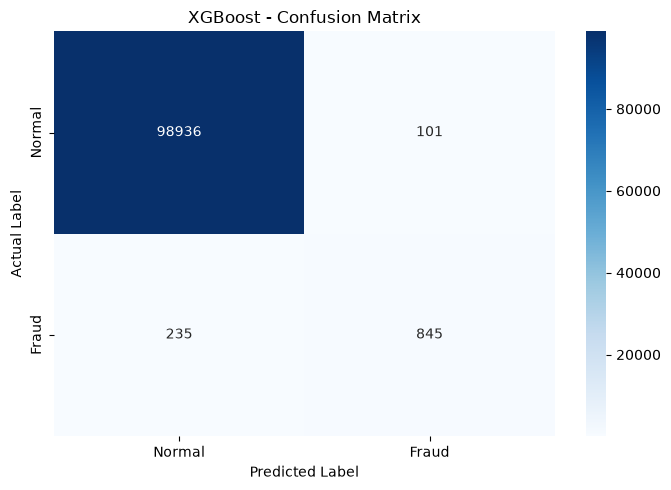

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# XGBoost - Confusion Matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.title("XGBoost - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

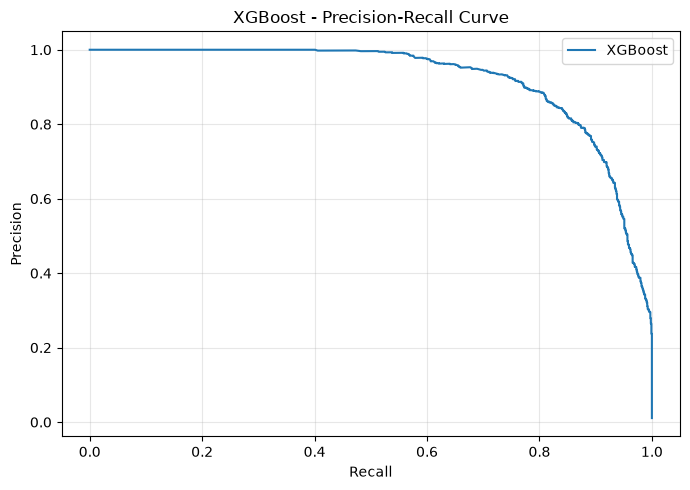

In [16]:
from sklearn.metrics import precision_recall_curve

# XGBoost - Precision-Recall Curve

precision_values, recall_values, _ = precision_recall_curve(
    y_test,
    test_probs
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall_values,
    precision_values,
    label="XGBoost"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("XGBoost - Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

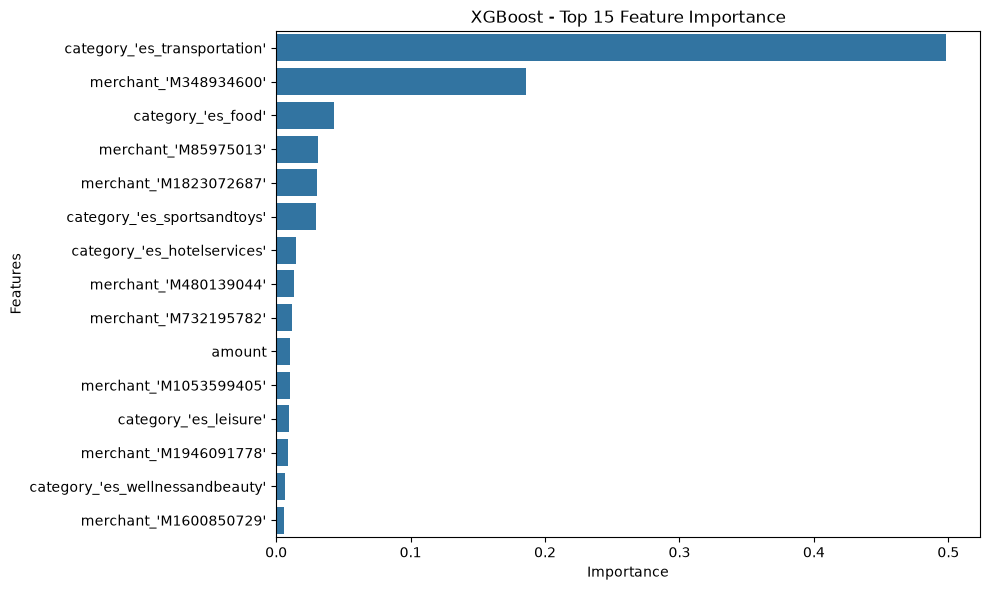

In [17]:
# XGBoost - Feature Importance

feature_importance = pd.Series(
    xgb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=feature_importance.head(15).values,
    y=feature_importance.head(15).index
)

plt.title("XGBoost - Top 15 Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

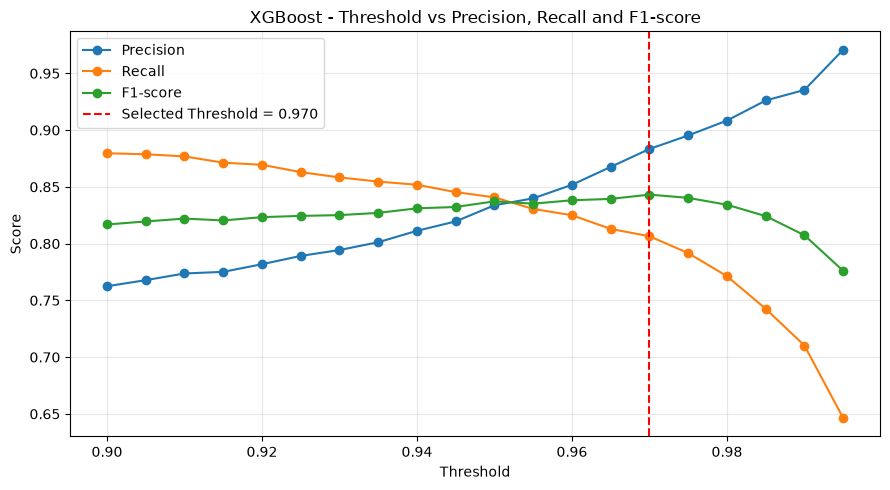

In [18]:
# XGBoost - Threshold vs Precision, Recall, F1-score

plt.figure(figsize=(9, 5))

plt.plot(
    fine_results_df["Threshold"],
    fine_results_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    fine_results_df["Threshold"],
    fine_results_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    fine_results_df["Threshold"],
    fine_results_df["F1-score"],
    marker="o",
    label="F1-score"
)

plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Selected Threshold = {best_threshold:.3f}"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("XGBoost - Threshold vs Precision, Recall and F1-score")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()